Impoerting Libraries


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Reading the Data

In [7]:
df=pd.read_csv("HR-Employee-Attrition.csv")

Exploring Data

In [8]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [9]:
df.tail()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [10]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [ ]:
Data Cleaning

In [12]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (df[col] < lower_bound) | (df[col] > upper_bound)

    outlier_summary.append({
        "Column": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": mask.sum(),
        "Outlier Percentage": round(mask.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df.sort_values(
    by="Outlier Count", ascending=False
)

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
20,TrainingTimesLastYear,0.500,4.500,238,16.19
15,PerformanceRating,3.000,3.000,226,15.37
11,MonthlyIncome,-5291.000,16581.000,114,7.76
24,YearsSinceLastPromotion,-4.500,7.500,107,7.28
22,YearsAtCompany,-6.000,18.000,104,7.07
18,StockOptionLevel,-1.500,2.500,85,5.78
19,TotalWorkingYears,-7.500,28.500,63,4.29
13,NumCompaniesWorked,-3.500,8.500,52,3.54
23,YearsInCurrentRole,-5.500,14.500,21,1.43
25,YearsWithCurrManager,-5.500,14.500,14,0.95


In [15]:
outlier_rows = pd.Series(False, index=df.index)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_rows |= (df[col] < lower) | (df[col] > upper)

outlier_records = df[outlier_rows]

print("Total rows:", len(df))
print("Rows containing outliers:", len(outlier_records))

outlier_records.head()

Total rows: 1470
Rows containing outliers: 691


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0


EDA

Analyze numerical feature

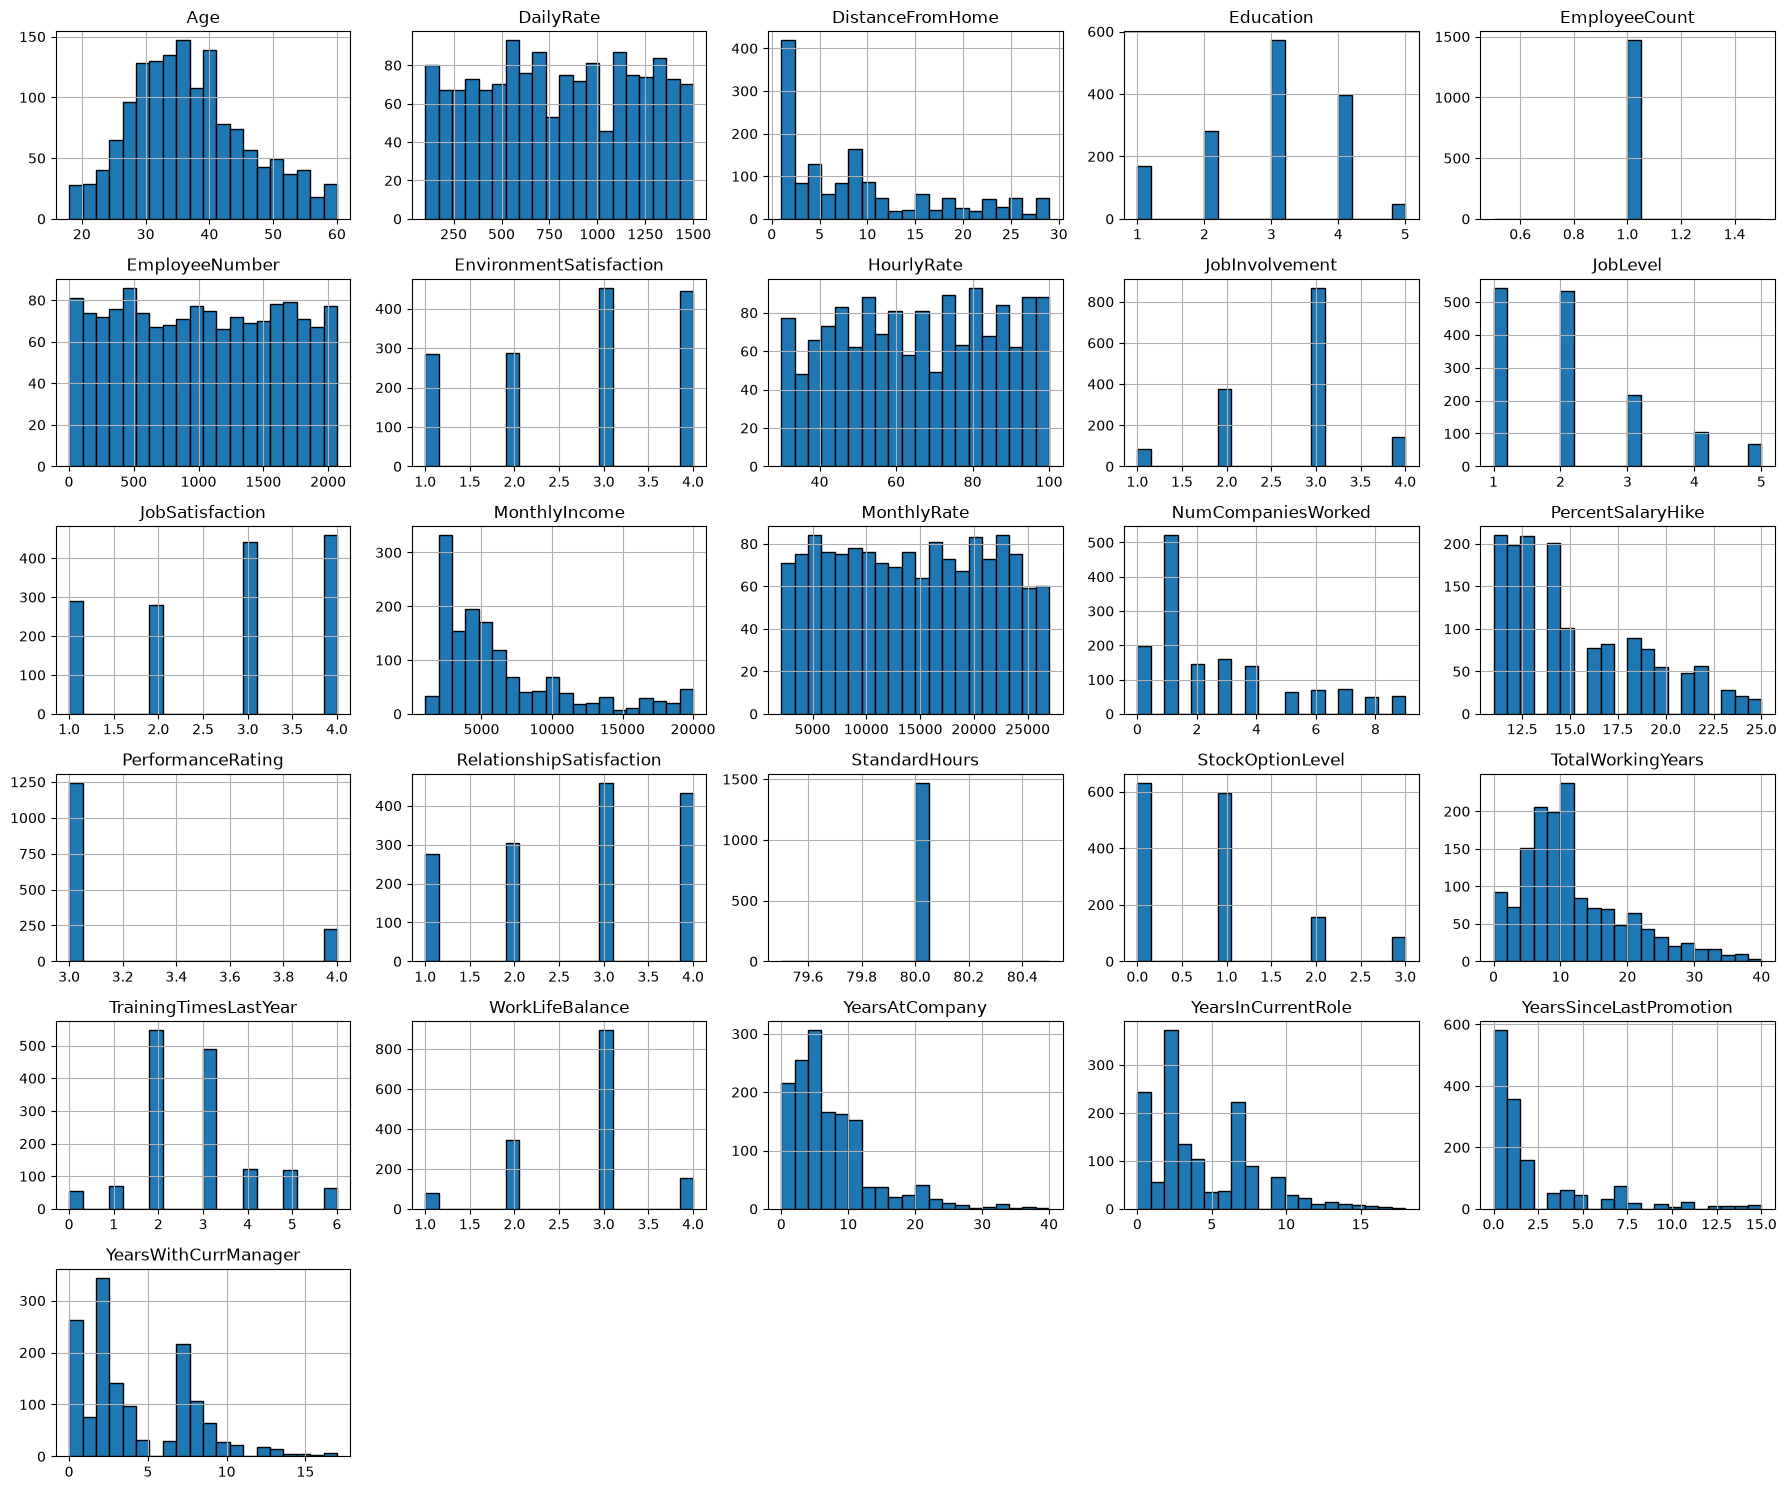

In [16]:
df[numeric_cols].hist(
    figsize=(18, 15),
    bins=20,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

Analyze categorical features

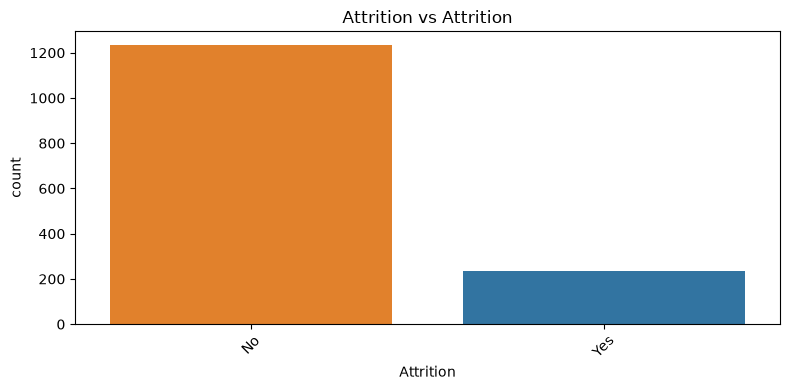

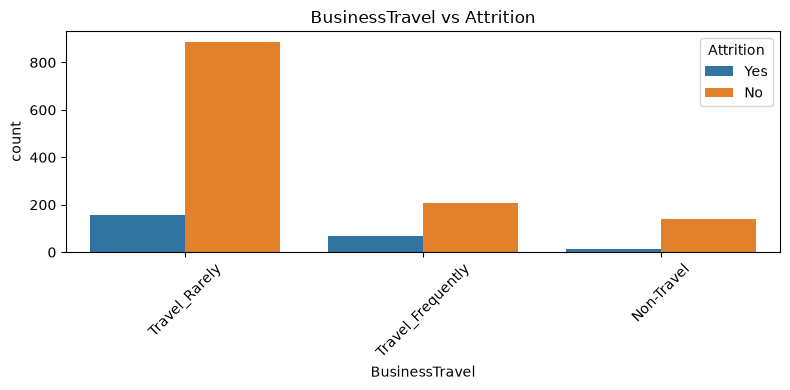

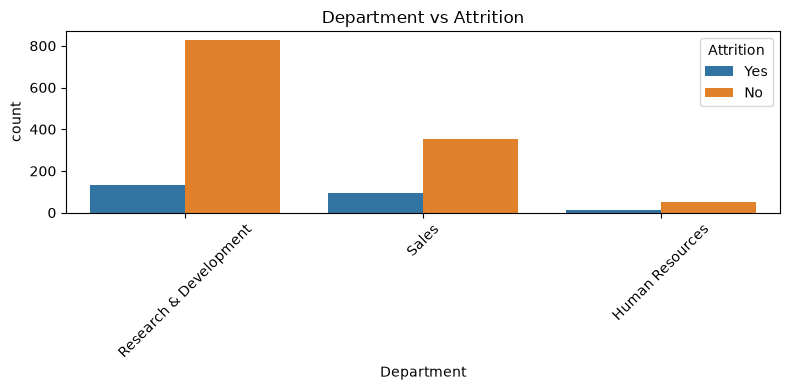

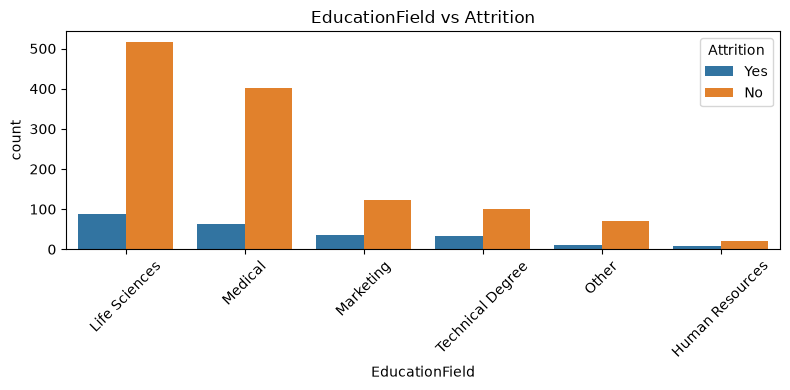

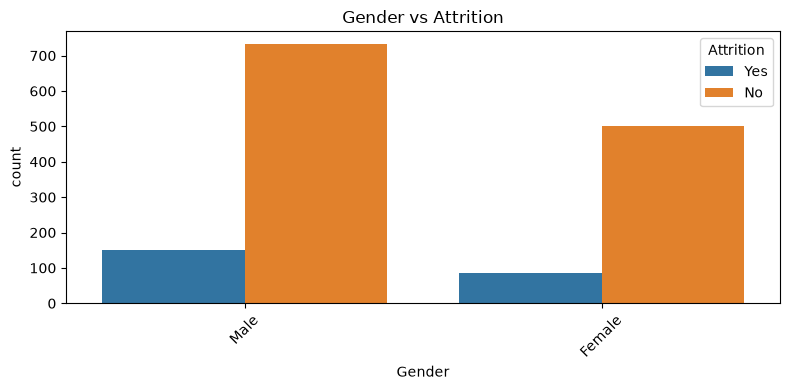

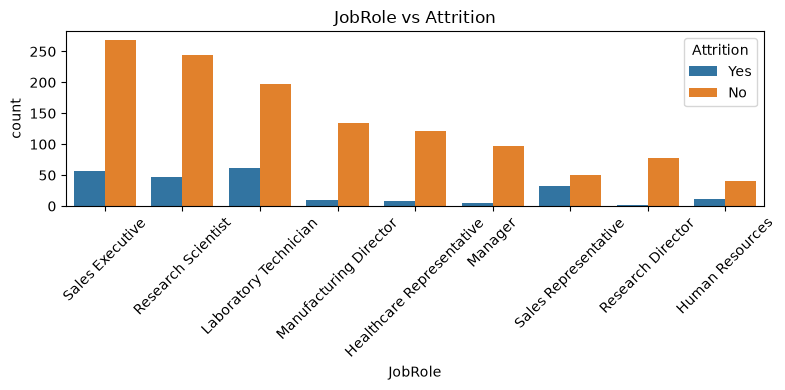

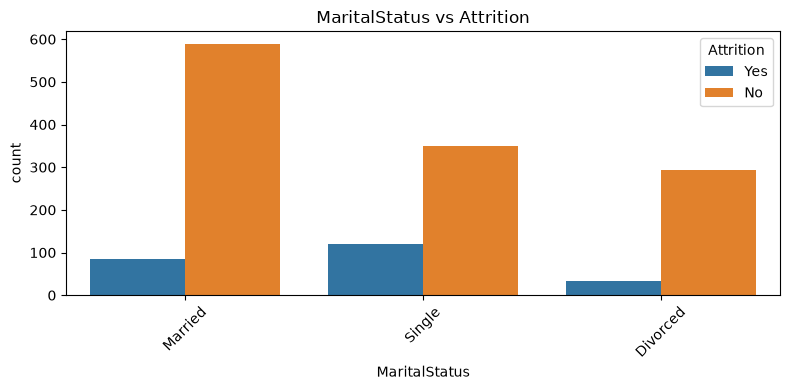

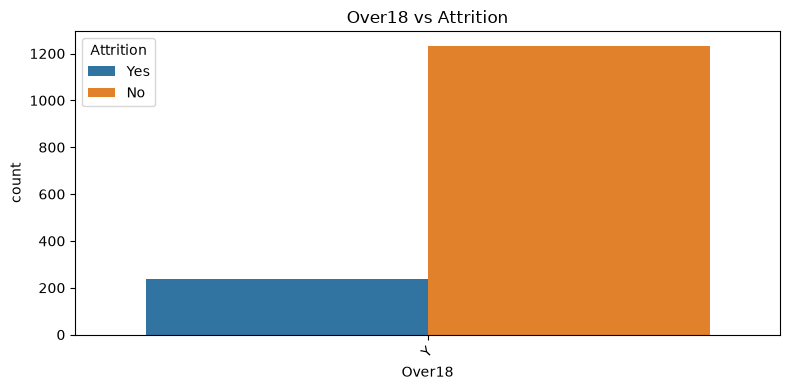

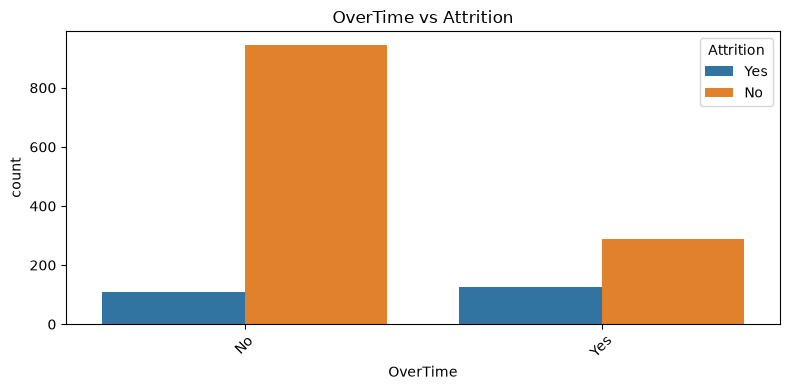

In [20]:
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'str']
).columns

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(
        data=df,
        x=col,
        hue='Attrition',
        order=df[col].value_counts().index
    )
    plt.title(f'{col} vs Attrition')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Correlation heatmap

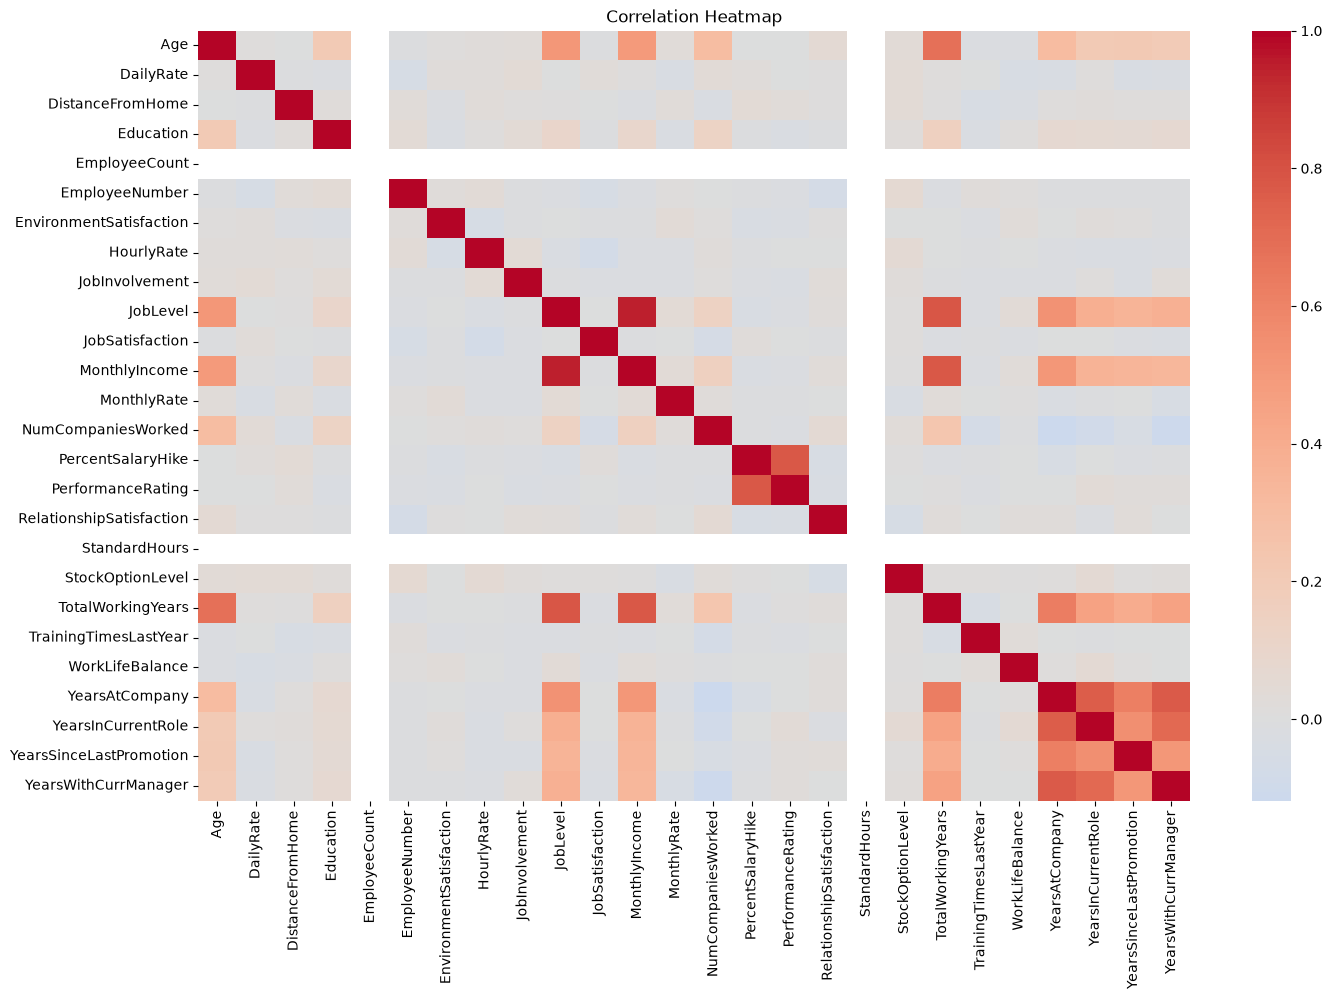

In [21]:
plt.figure(figsize=(16, 10))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.show()

 Check unique values in every column

In [23]:
for col in df.columns:
    print(col, ":", df[col].nunique())

Age : 43
Attrition : 2
BusinessTravel : 3
DailyRate : 886
Department : 3
DistanceFromHome : 29
Education : 5
EducationField : 6
EmployeeCount : 1
EmployeeNumber : 1470
EnvironmentSatisfaction : 4
Gender : 2
HourlyRate : 71
JobInvolvement : 4
JobLevel : 5
JobRole : 9
JobSatisfaction : 4
MaritalStatus : 3
MonthlyIncome : 1349
MonthlyRate : 1427
NumCompaniesWorked : 10
Over18 : 1
OverTime : 2
PercentSalaryHike : 15
PerformanceRating : 2
RelationshipSatisfaction : 4
StandardHours : 1
StockOptionLevel : 4
TotalWorkingYears : 40
TrainingTimesLastYear : 7
WorkLifeBalance : 4
YearsAtCompany : 37
YearsInCurrentRole : 19
YearsSinceLastPromotion : 16
YearsWithCurrManager : 18


Check class imbalance

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


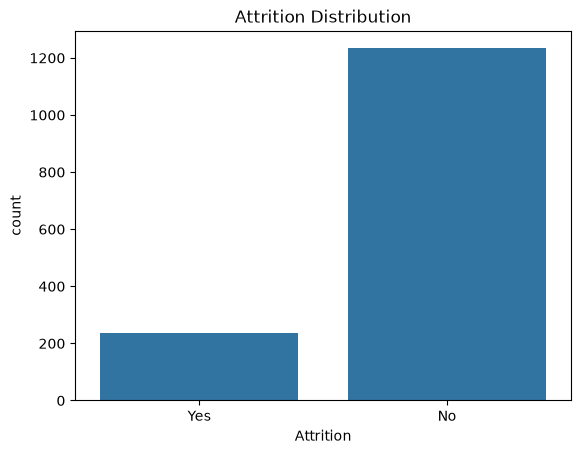

In [24]:
print(df['Attrition'].value_counts())
print(df['Attrition'].value_counts(normalize=True).mul(100).round(2))

sns.countplot(data=df, x='Attrition')
plt.title('Attrition Distribution')
plt.show()

Compare numerical features by attrition

In [25]:
features = [
    'Age', 'MonthlyIncome', 'TotalWorkingYears',
    'YearsAtCompany', 'DistanceFromHome'
]

display(df.groupby('Attrition')[features].mean().T)

Attrition,No,Yes
Age,37.561233,33.607595
MonthlyIncome,6832.739659,4787.092827
TotalWorkingYears,11.862936,8.244726
YearsAtCompany,7.369019,5.130802
DistanceFromHome,8.915653,10.632911


Calculate attrition rates by department

Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64


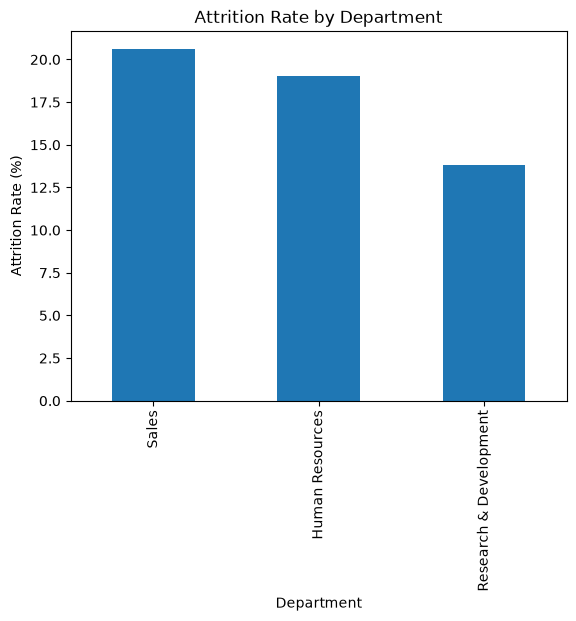

In [26]:
department_rate = (
    df.groupby('Department')['Attrition']
    .apply(lambda x: x.eq('Yes').mean() * 100)
    .sort_values(ascending=False)
)

print(department_rate)

department_rate.plot(kind='bar', title='Attrition Rate by Department')
plt.ylabel('Attrition Rate (%)')
plt.show()

Analyze overtime and attrition

Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


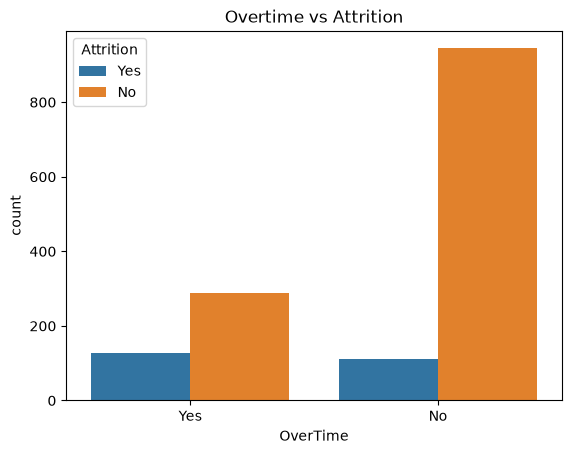

In [27]:
overtime_rate = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

display(overtime_rate.round(2))

sns.countplot(data=df, x='OverTime', hue='Attrition')
plt.title('Overtime vs Attrition')
plt.show()

Analyze attrition by job role

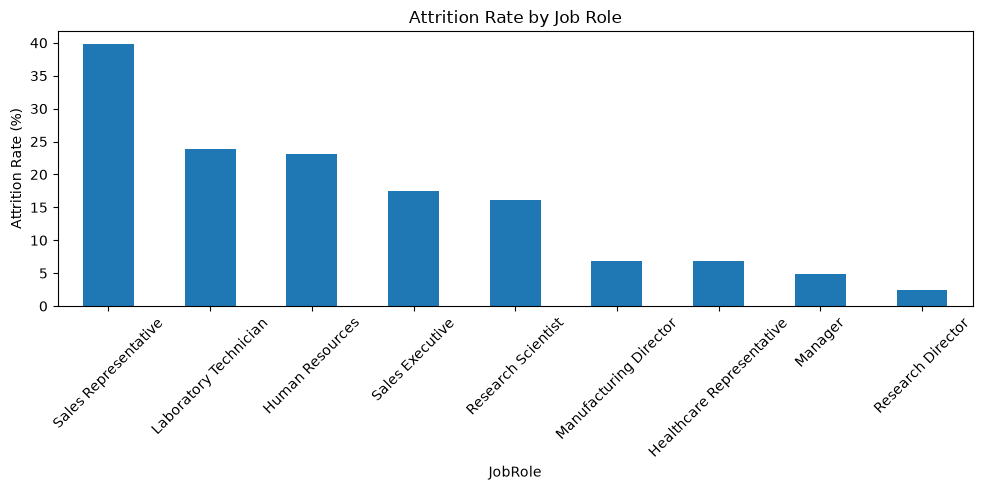

In [28]:
role_rate = (
    df.groupby('JobRole')['Attrition']
    .apply(lambda x: x.eq('Yes').mean() * 100)
    .sort_values(ascending=False)
)

role_rate.plot(kind='bar', figsize=(10, 5))
plt.title('Attrition Rate by Job Role')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Analyze age group

AgeGroup
18-25    35.772358
26-35    19.141914
36-45     9.188034
46-55    11.504425
56-65    17.021277
Name: Attrition, dtype: float64


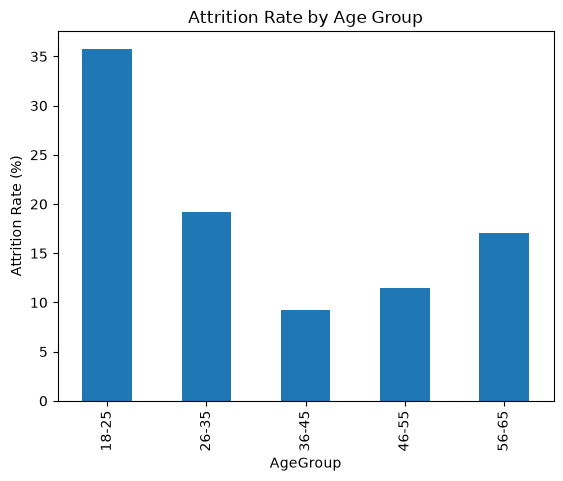

In [29]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[18, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65'],
    include_lowest=True
)

age_rate = (
    df.groupby('AgeGroup', observed=False)['Attrition']
    .apply(lambda x: x.eq('Yes').mean() * 100)
)

print(age_rate)

age_rate.plot(kind='bar', title='Attrition Rate by Age Group')
plt.ylabel('Attrition Rate (%)')
plt.show()

Analyze salary groups

In [30]:
df['IncomeGroup'] = pd.qcut(
    df['MonthlyIncome'],
    q=4,
    duplicates='drop'
)

income_rate = (
    df.groupby('IncomeGroup', observed=False)['Attrition']
    .apply(lambda x: x.eq('Yes').mean() * 100)
)

print(income_rate)

IncomeGroup
(1008.999, 2911.0]    29.268293
(2911.0, 4919.0]      14.207650
(4919.0, 8379.0]      10.626703
(8379.0, 19999.0]     10.326087
Name: Attrition, dtype: float64


Analyze satisfaction scores

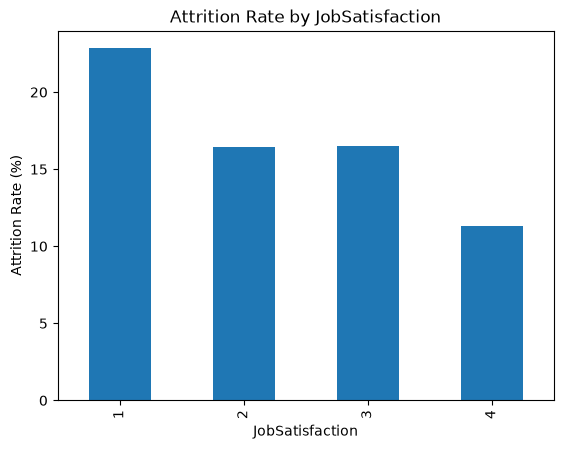

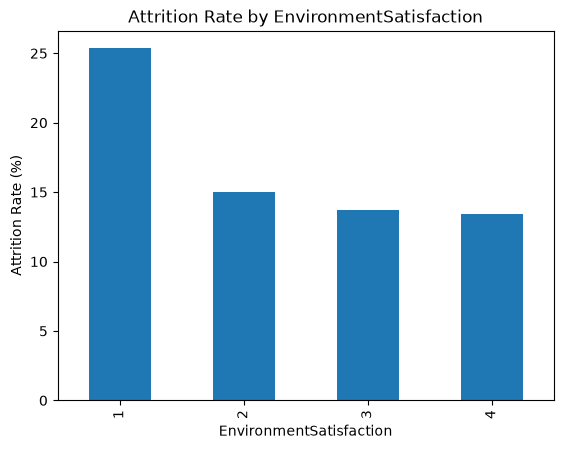

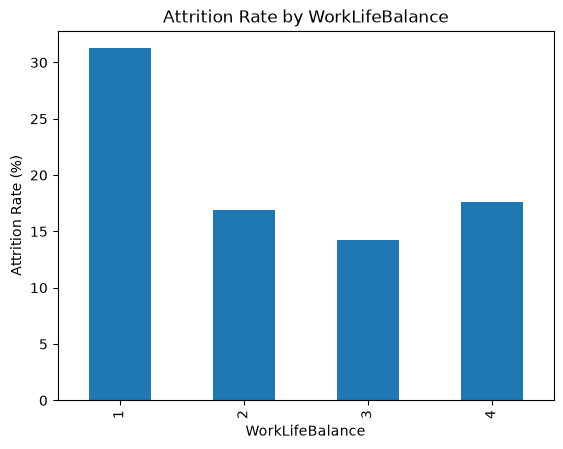

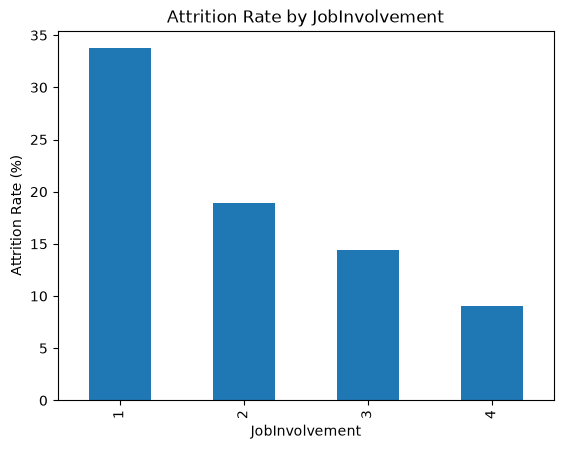

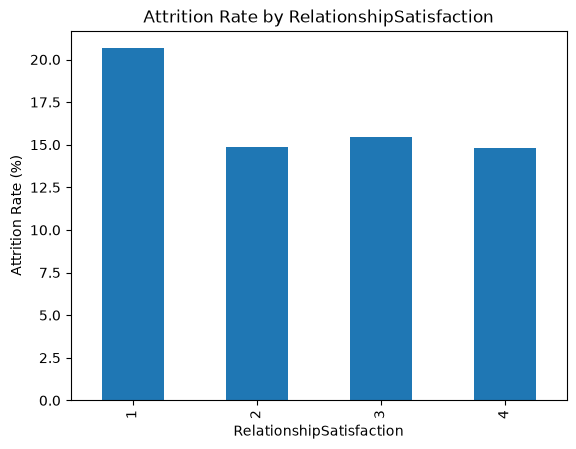

In [31]:
features = [
    'JobSatisfaction',
    'EnvironmentSatisfaction',
    'WorkLifeBalance',
    'JobInvolvement',
    'RelationshipSatisfaction'
]

for col in features:
    rate = (
        df.groupby(col)[ 'Attrition' ]
        .apply(lambda x: x.eq('Yes').mean() * 100)
    )

    rate.plot(kind='bar', title=f'Attrition Rate by {col}')
    plt.ylabel('Attrition Rate (%)')
    plt.show()

Analyze promotion and career growth

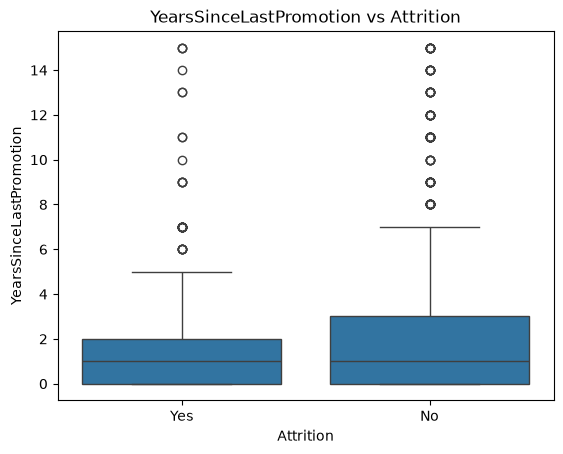

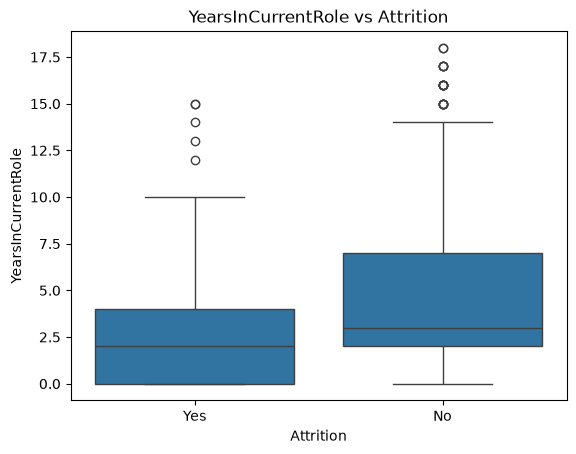

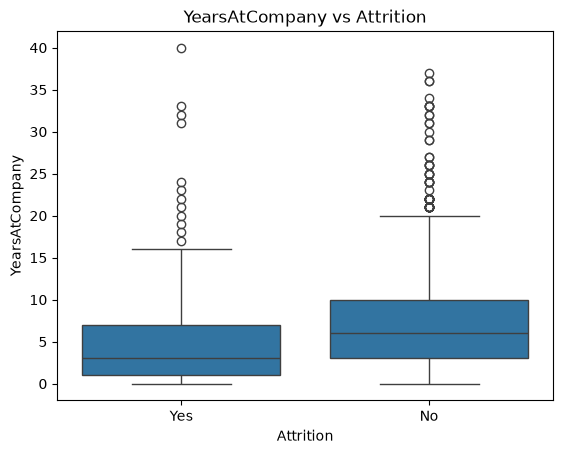

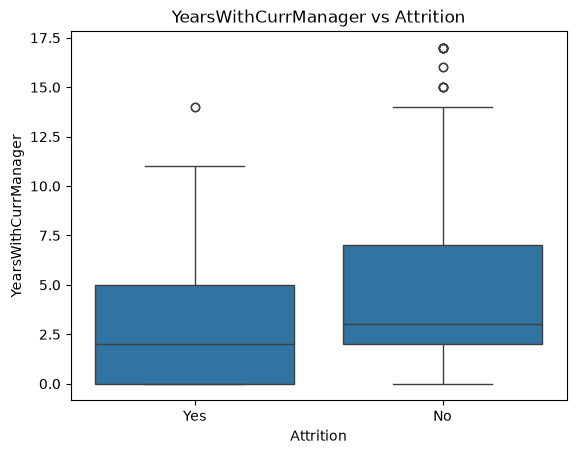

In [32]:
features = [
    'YearsSinceLastPromotion',
    'YearsInCurrentRole',
    'YearsAtCompany',
    'YearsWithCurrManager'
]

for col in features:
    sns.boxplot(data=df, x='Attrition', y=col)
    plt.title(f'{col} vs Attrition')
    plt.show()

Statistical significance test

In [33]:
from scipy.stats import mannwhitneyu

features = ['Age', 'MonthlyIncome', 'YearsAtCompany']

for col in features:
    yes = df.loc[df['Attrition'] == 'Yes', col].dropna()
    no = df.loc[df['Attrition'] == 'No', col].dropna()

    stat, p = mannwhitneyu(yes, no, alternative='two-sided')

    print(f'{col}: p-value = {p:.4f}')

Age: p-value = 0.0000
MonthlyIncome: p-value = 0.0000
YearsAtCompany: p-value = 0.0000


Install the required libraries

In [35]:
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

Prepare the data

In [36]:
X = df.drop(columns=[
    'Attrition', 'EmployeeNumber',
    'EmployeeCount', 'StandardHours', 'Over18'
], errors='ignore')

y = df['Attrition'].map({'No': 0, 'Yes': 1})

valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Create preprocessing pipeline

In [37]:
num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(exclude='number').columns

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

Train the model with MLflow tracking

In [44]:

mlflow.set_experiment("Employee_Attrition")

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

with mlflow.start_run(run_name="Random_Forest"):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)

    mlflow.log_params({
        "n_estimators": 100,
        "random_state": 42,
        "class_weight": "balanced"
    })

    mlflow.log_metrics({
        "accuracy": accuracy,
        "f1_score": f1,
        "recall": recall
    })

    mlflow.sklearn.log_model(
        sk_model=model,
        artifact_path="model",
        serialization_format="cloudpickle"
    )

    run_id = mlflow.active_run().info.run_id

    print("Model logged successfully!")
    print("Run ID:", run_id)
    print("Accuracy:", accuracy)
    print("F1 score:", f1)
    print("Recall:", recall)


2026/10/22 17:07:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/22 17:07:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Model logged successfully!
Run ID: 140299b8b08f446da2d487bbc79212b0
Accuracy: 0.8231292517006803
F1 score: 0.35
Recall: 0.2978723404255319


In [46]:
runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition"]
)

display(runs[['run_id', 'metrics.accuracy', 'metrics.f1_score']])

,run_id,metrics.accuracy,metrics.f1_score
0,140299b8b08f446da2d487bbc79212b0,0.823129,0.35
1,27d9eade57104d92ada9ba305bf3c102,0.823129,0.35
2,bc0d6c5049f8453f89e6af72616efee3,0.823129,0.35
3,67a8b70b86fe4813bbef3df05478df47,0.823129,0.35


In [47]:
run_id = runs.iloc[0]['run_id']

loaded_model = mlflow.sklearn.load_model(
    f"runs:/{run_id}/model"
)

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

In [59]:

models = {
    "Logistic_Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision_Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient_Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

mlflow.set_experiment("Employee_Attrition")


<Experiment: artifact_location='file:c:/Users/ASUS/OneDrive/Desktop/ml/mlruns/1', creation_time=1792668814254, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792668814254, lifecycle_stage='active', name='Employee_Attrition', tags={}, trace_location=None, workspace='default'>

In [58]:
results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    with mlflow.start_run(run_name=name):

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        metrics = {
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "f1_score": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_test, y_prob)
        }

        mlflow.log_param("model_name", name)
        mlflow.log_params(classifier.get_params())
        mlflow.log_metrics(metrics)

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="cloudpickle"
        )

        results.append({
            "Model": name,
            **metrics
        })

        print(f"Completed: {name}")

results_df = pd.DataFrame(results)
display(results_df.sort_values("f1_score", ascending=False))

2026/10/22 17:19:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Completed: Logistic_Regression


2026/10/22 17:20:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Completed: Decision_Tree


2026/10/22 17:20:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Completed: Gradient_Boosting


,Model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
1,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015
2,Gradient_Boosting,0.863946,0.769231,0.212766,0.333333,0.800930


 View all experiments in MLflow

In [52]:
runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition"]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.accuracy",
            "metrics.precision",
            "metrics.recall",
            "metrics.f1_score",
            "metrics.roc_auc"
        ]
    ].sort_values("metrics.f1_score", ascending=False)
)

,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
2,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
1,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015
4,Random_Forest,0.823129,NaN,0.297872,0.350000,NaN
6,Random_Forest,0.823129,NaN,0.297872,0.350000,NaN
5,Random_Forest,0.823129,NaN,0.297872,0.350000,NaN
7,Random_Forest,0.823129,NaN,0.297872,0.350000,NaN
0,Gradient_Boosting,0.863946,0.769231,0.212766,0.333333,0.800930
3,Logistic_Regression,NaN,NaN,NaN,NaN,NaN


In [60]:
# Predict using your trained model
y_pred = pipeline.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
1061,0,0
891,0,0
456,0,0
922,0,0
69,1,0
1164,0,0
406,0,0
1330,0,0
1232,0,0
1311,0,0


Check prediction accuracy   

In [61]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Attrition', 'Attrition']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8639455782312925

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.87      0.99      0.92       247
   Attrition       0.77      0.21      0.33        47

    accuracy                           0.86       294
   macro avg       0.82      0.60      0.63       294
weighted avg       0.85      0.86      0.83       294


Confusion Matrix:
[[244   3]
 [ 37  10]]


Predict attrition probability

In [62]:
y_prob = pipeline.predict_proba(X_test)[:, 1]

prediction_results = pd.DataFrame({
    'Actual': y_test.map({0: 'No', 1: 'Yes'}),
    'Predicted': pd.Series(y_pred, index=y_test.index).map({
        0: 'No',
        1: 'Yes'
    }),
    'Attrition_Probability': y_prob
})

prediction_results.head(10)

,Actual,Predicted,Attrition_Probability
1061,No,No,0.329262
891,No,No,0.016101
456,No,No,0.167862
922,No,No,0.009124
69,Yes,No,0.233403
1164,No,No,0.091889
406,No,No,0.066736
1330,No,No,0.056888
1232,No,No,0.016966
1311,No,No,0.313983


Load the model from MLflow and predict

In [63]:
runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition"]
)

display(runs[
    ['run_id', 'tags.mlflow.runName', 'metrics.f1_score']
])

,run_id,tags.mlflow.runName,metrics.f1_score
0,6164fed3295446d5b118a361ac26cfaa,Gradient_Boosting,0.333333
1,5a0e8480e1d940f89ee9fe4523f67997,Decision_Tree,0.434783
2,c10afd79b03f47e98587467daca1d60e,Logistic_Regression,0.481203
3,117a6e03a9ba43129e688c8c6b67bef2,Logistic_Regression,0.481203
4,d867fa79fe244a5ea78fccc4ceebe093,Gradient_Boosting,0.333333
5,9ea36aa41c444d8698a84e5b34b9647d,Decision_Tree,0.434783
6,c83baa1acc4f412fbc13ff4b56eace4b,Logistic_Regression,0.481203
7,6abdd114891f48ebb2f8d206bd1018ee,Gradient_Boosting,0.333333
8,ecb0ad92f21c4a4f9d30a277050d4aa2,Decision_Tree,0.434783
9,074771e094c04b7ca757e19cdb133b47,Logistic_Regression,0.481203


Select the run ID corresponding to the model you want

In [69]:
run_id ="6164fed3295446d5b118a361ac26cfaa"


loaded_model = mlflow.sklearn.load_model(
    f"runs:/{run_id}/model"
)

predictions = loaded_model.predict(X_test.head(5))

print(predictions)

[0 0 0 0 0]


Predict for a new employee

In [65]:
new_employee = X_test.head(1).copy()

prediction = loaded_model.predict(new_employee)[0]
probability = loaded_model.predict_proba(new_employee)[0, 1]

print("Prediction:", "Yes" if prediction == 1 else "No")
print(f"Attrition probability: {probability:.2%}")

Prediction: Yes
Attrition probability: 65.00%


a user-input form in Python

In [ ]:

import pandas as pd

# Enter employee details
employee = {}

for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        value = input(f"Enter {col} (example: {X[col].median():.0f}): ")
        employee[col] = float(value)
    else:
        options = X[col].dropna().unique().tolist()
        value = input(
            f"Enter {col} {options}: "
        )
        employee[col] = value

# Create DataFrame with the correct feature order
new_employee = pd.DataFrame([employee], columns=X.columns)

# Predict
prediction = loaded_model.predict(new_employee)[0]
probability = loaded_model.predict_proba(new_employee)[0, 1]

print("\n--- Attrition Prediction ---")
print("Prediction:", "Yes - Likely to Leave" if prediction == 1 else "No - Likely to Stay")
print(f"Predicted attrition probability: {probability:.2%}")



--- Attrition Prediction ---
Prediction: No - Likely to Stay
Predicted attrition probability: 40.00%


In [71]:
import mlflow

runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition"]
)

display(
    runs[
        [
            "run_id",
            "tags.mlflow.runName",
            "metrics.accuracy",
            "metrics.f1_score",
            "metrics.recall"
        ]
    ].sort_values("metrics.f1_score", ascending=False)
)

,run_id,tags.mlflow.runName,metrics.accuracy,metrics.f1_score,metrics.recall
3,117a6e03a9ba43129e688c8c6b67bef2,Logistic_Regression,0.765306,0.481203,0.680851
2,c10afd79b03f47e98587467daca1d60e,Logistic_Regression,0.765306,0.481203,0.680851
13,67f20afbdca3401cba7d689ddb9aa07b,Logistic_Regression,0.765306,0.481203,0.680851
10,6024e6d8f8c74103b14d7d90191ee49a,Logistic_Regression,0.765306,0.481203,0.680851
9,074771e094c04b7ca757e19cdb133b47,Logistic_Regression,0.765306,0.481203,0.680851
6,c83baa1acc4f412fbc13ff4b56eace4b,Logistic_Regression,0.765306,0.481203,0.680851
12,e1ec77521ba14ada9687bf977995c2d4,Decision_Tree,0.778912,0.434783,0.531915
1,5a0e8480e1d940f89ee9fe4523f67997,Decision_Tree,0.778912,0.434783,0.531915
8,ecb0ad92f21c4a4f9d30a277050d4aa2,Decision_Tree,0.778912,0.434783,0.531915
5,9ea36aa41c444d8698a84e5b34b9647d,Decision_Tree,0.778912,0.434783,0.531915


Compare all trained models

In [72]:
import mlflow
import mlflow.sklearn
import pandas as pd

runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition"]
)

columns = [
    "run_id",
    "tags.mlflow.runName",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.roc_auc"
]

results = runs[
    [col for col in columns if col in runs.columns]
]

display(
    results.sort_values(
        "metrics.f1_score",
        ascending=False
    )
)

,run_id,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
3,117a6e03a9ba43129e688c8c6b67bef2,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
2,c10afd79b03f47e98587467daca1d60e,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
13,67f20afbdca3401cba7d689ddb9aa07b,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
10,6024e6d8f8c74103b14d7d90191ee49a,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
9,074771e094c04b7ca757e19cdb133b47,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
6,c83baa1acc4f412fbc13ff4b56eace4b,Logistic_Regression,0.765306,0.372093,0.680851,0.481203,0.822207
12,e1ec77521ba14ada9687bf977995c2d4,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015
1,5a0e8480e1d940f89ee9fe4523f67997,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015
8,ecb0ad92f21c4a4f9d30a277050d4aa2,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015
5,9ea36aa41c444d8698a84e5b34b9647d,Decision_Tree,0.778912,0.367647,0.531915,0.434783,0.659015


Select the best model
This selects the model with the highest recorded F1-score.

In [73]:
valid_runs = runs.dropna(
    subset=["metrics.f1_score"]
)

best_run = valid_runs.loc[
    valid_runs["metrics.f1_score"].idxmax()
]

best_run_id = best_run["run_id"]

print("Best Model:", best_run["tags.mlflow.runName"])
print("Run ID:", best_run_id)
print("Accuracy:", best_run["metrics.accuracy"])
print("Precision:", best_run["metrics.precision"])
print("Recall:", best_run["metrics.recall"])
print("F1-score:", best_run["metrics.f1_score"])

Best Model: Logistic_Regression
Run ID: c10afd79b03f47e98587467daca1d60e
Accuracy: 0.7653061224489796
Precision: 0.37209302325581395
Recall: 0.6808510638297872
F1-score: 0.48120300751879697


Load the selected mode

In [74]:
best_model = mlflow.sklearn.load_model(
    f"runs:/{best_run_id}/model"
)

print("Model loaded successfully!")

Model loaded successfully!


Check the expected features

In [75]:
if hasattr(best_model, "feature_names_in_"):
    print(best_model.feature_names_in_)
else:
    print("Inspect the preprocessing pipeline to identify input features.")

['Age' 'BusinessTravel' 'DailyRate' 'Department' 'DistanceFromHome'
 'Education' 'EducationField' 'EnvironmentSatisfaction' 'Gender'
 'HourlyRate' 'JobInvolvement' 'JobLevel' 'JobRole' 'JobSatisfaction'
 'MaritalStatus' 'MonthlyIncome' 'MonthlyRate' 'NumCompaniesWorked'
 'OverTime' 'PercentSalaryHike' 'PerformanceRating'
 'RelationshipSatisfaction' 'StockOptionLevel' 'TotalWorkingYears'
 'TrainingTimesLastYear' 'WorkLifeBalance' 'YearsAtCompany'
 'YearsInCurrentRole' 'YearsSinceLastPromotion' 'YearsWithCurrManager'
 'AgeGroup' 'IncomeGroup']


In [76]:
predictions = best_model.predict(X_test.head(5))

print("Predictions:", predictions)

Predictions: [0 0 0 0 0]


In [90]:


features = [
    "Age",
    "Department",
    "JobRole",
    "MonthlyIncome",
    "OverTime",
    "JobSatisfaction"
]

X6 = df[features].copy()
y = df["Attrition"].map({"No": 0, "Yes": 1})

valid = y.notna()
X6 = X6.loc[valid]
y = y.loc[valid].astype(int)

numeric_cols = ["Age", "MonthlyIncome", "JobSatisfaction"]
categorical_cols = ["Department", "JobRole", "OverTime"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train6, X_test6, y_train6, y_test6 = train_test_split(
    X6, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic_Regression_6F": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random_Forest_6F": RandomForestClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42
    ),
    "Gradient_Boosting_6F": GradientBoostingClassifier(
        random_state=42
    )
}

mlflow.set_experiment("Employee_Attrition_6_Features")

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    with mlflow.start_run(run_name=name):
        pipeline.fit(X_train6, y_train6)

        pred = pipeline.predict(X_test6)
        prob = pipeline.predict_proba(X_test6)[:, 1]

        metrics = {
            "accuracy": accuracy_score(y_test6, pred),
            "precision": precision_score(y_test6, pred, zero_division=0),
            "recall": recall_score(y_test6, pred, zero_division=0),
            "f1_score": f1_score(y_test6, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test6, prob)
        }

        mlflow.log_param("feature_count", 6)
        mlflow.log_params(classifier.get_params())
        mlflow.log_metrics(metrics)

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="cloudpickle"
        )

        results.append({
            "Model": name,
            "run_id": mlflow.active_run().info.run_id,
            **metrics
        })

results6 = pd.DataFrame(results)
display(results6.sort_values("f1_score", ascending=False))


c:\Users\ASUS\OneDrive\Desktop\ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
2026/10/22 18:21:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence

,Model,run_id,accuracy,precision,recall,f1_score,roc_auc
0,Logistic_Regression_6F,f1c557ab55bb48938b644c5c4e1d1ca2,0.687075,0.293578,0.680851,0.410256,0.730123
1,Random_Forest_6F,f6f06f98ab0a413bbd423793969e88ab,0.799320,0.363636,0.340426,0.351648,0.706305
2,Gradient_Boosting_6F,e1272668606c460fb125ea76b79b2a69,0.843537,0.526316,0.212766,0.303030,0.711302


In [81]:



# Get all runs from the 6-feature experiment
runs = mlflow.search_runs(
    experiment_names=["Employee_Attrition_6_Features"]
)

# Select the run with the highest F1-score
runs = runs.dropna(subset=["metrics.f1_score"])
best_run = runs.loc[runs["metrics.f1_score"].idxmax()]

# Load the best model
best_run_id = best_run["run_id"]

best_model = mlflow.sklearn.load_model(
    f"runs:/{best_run_id}/model"
)

print("Best model loaded successfully!")
print("Model:", best_run["tags.mlflow.runName"])
print("F1-score:", best_run["metrics.f1_score"])
print("Run ID:", best_run_id)

Best model loaded successfully!
Model: Logistic_Regression_6F
F1-score: 0.41025641025641024
Run ID: f722fec74b9f4b9dae3f04e06acb873c
